In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Import the data
* Import data that describe countries in one point

In [12]:
one_point_diff_3countries_deleted = pd.read_parquet('../data/diff_then_one_point_countries_then_delete_zeros_3_countries_deleted.parquet')

In [13]:
one_point_diff_3countries_deleted.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_skew,labor_force_kurtosis,labor_force_trend,...,edu_spending_df_trend,govermment_effective_df_mean,govermment_effective_df_median,govermment_effective_df_std,govermment_effective_df_cv,govermment_effective_df_min,govermment_effective_df_max,govermment_effective_df_skew,govermment_effective_df_kurtosis,govermment_effective_df_trend
0,Australia,0.177,0.245,0.154858,0.874904,-0.01,0.43,-0.055214,-1.470372,0.014727,...,-0.002970,0.006,0.00,0.047582,7.930252,-0.10,0.06,-0.714489,0.008940,0.002667
1,Austria,0.026,0.025,0.029732,1.143544,-0.02,0.07,0.139709,-1.244774,0.004121,...,-0.016061,-0.014,0.00,0.064529,-4.609219,-0.13,0.12,0.178013,0.092429,-0.008364
2,Belgium,0.042,0.050,0.042379,1.009030,-0.02,0.11,0.034370,-1.356918,0.003152,...,-0.003455,-0.036,-0.01,0.090465,-2.512930,-0.19,0.14,-0.036566,-0.315602,0.002061
3,Brazil,0.490,0.600,2.586797,5.279178,-6.21,4.11,-1.395227,1.933179,0.020121,...,-0.004364,-0.030,-0.01,0.137695,-4.589844,-0.24,0.29,0.712911,0.705002,0.000848
4,Bulgaria,-0.018,-0.015,0.057585,-3.199151,-0.12,0.09,0.129332,-0.434776,-0.010182,...,0.006667,-0.004,0.00,0.162247,-40.561681,-0.38,0.32,-0.457424,1.491768,0.008242


### Develop Cluster KMeans++
* With elbow method
* With silhouette plot for quality
* Export df with country, iso_a3, cluster category and continent in parquet format, manage missing values before importing

In [7]:
from sklearn.cluster import KMeans

#### one_point_diff_3countries_deleted

In [15]:
input_diff_3countries_deleted = one_point_diff_3countries_deleted.select_dtypes(include='number')
input_diff_3countries_deleted.head()

,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_skew,labor_force_kurtosis,labor_force_trend,livestock_prod_mean,...,edu_spending_df_trend,govermment_effective_df_mean,govermment_effective_df_median,govermment_effective_df_std,govermment_effective_df_cv,govermment_effective_df_min,govermment_effective_df_max,govermment_effective_df_skew,govermment_effective_df_kurtosis,govermment_effective_df_trend
0,0.177,0.245,0.154858,0.874904,-0.01,0.43,-0.055214,-1.470372,0.014727,-1.49,...,-0.002970,0.006,0.00,0.047582,7.930252,-0.10,0.06,-0.714489,0.008940,0.002667
1,0.026,0.025,0.029732,1.143544,-0.02,0.07,0.139709,-1.244774,0.004121,-0.08,...,-0.016061,-0.014,0.00,0.064529,-4.609219,-0.13,0.12,0.178013,0.092429,-0.008364
2,0.042,0.050,0.042379,1.009030,-0.02,0.11,0.034370,-1.356918,0.003152,0.02,...,-0.003455,-0.036,-0.01,0.090465,-2.512930,-0.19,0.14,-0.036566,-0.315602,0.002061
3,0.490,0.600,2.586797,5.279178,-6.21,4.11,-1.395227,1.933179,0.020121,0.93,...,-0.004364,-0.030,-0.01,0.137695,-4.589844,-0.24,0.29,0.712911,0.705002,0.000848
4,-0.018,-0.015,0.057585,-3.199151,-0.12,0.09,0.129332,-0.434776,-0.010182,-1.02,...,0.006667,-0.004,0.00,0.162247,-40.561681,-0.38,0.32,-0.457424,1.491768,0.008242


#### Using the elbow method to find the optimal number of clusters

In [9]:
distortions = []

In [10]:
import time

In [11]:
# Parameters
n_init_list = [10, 20]
max_iter_list = [100, 500]
n_clusters_range = range(1, 11)
random_states = [21, 42]


Running elbow plots for random_state=21


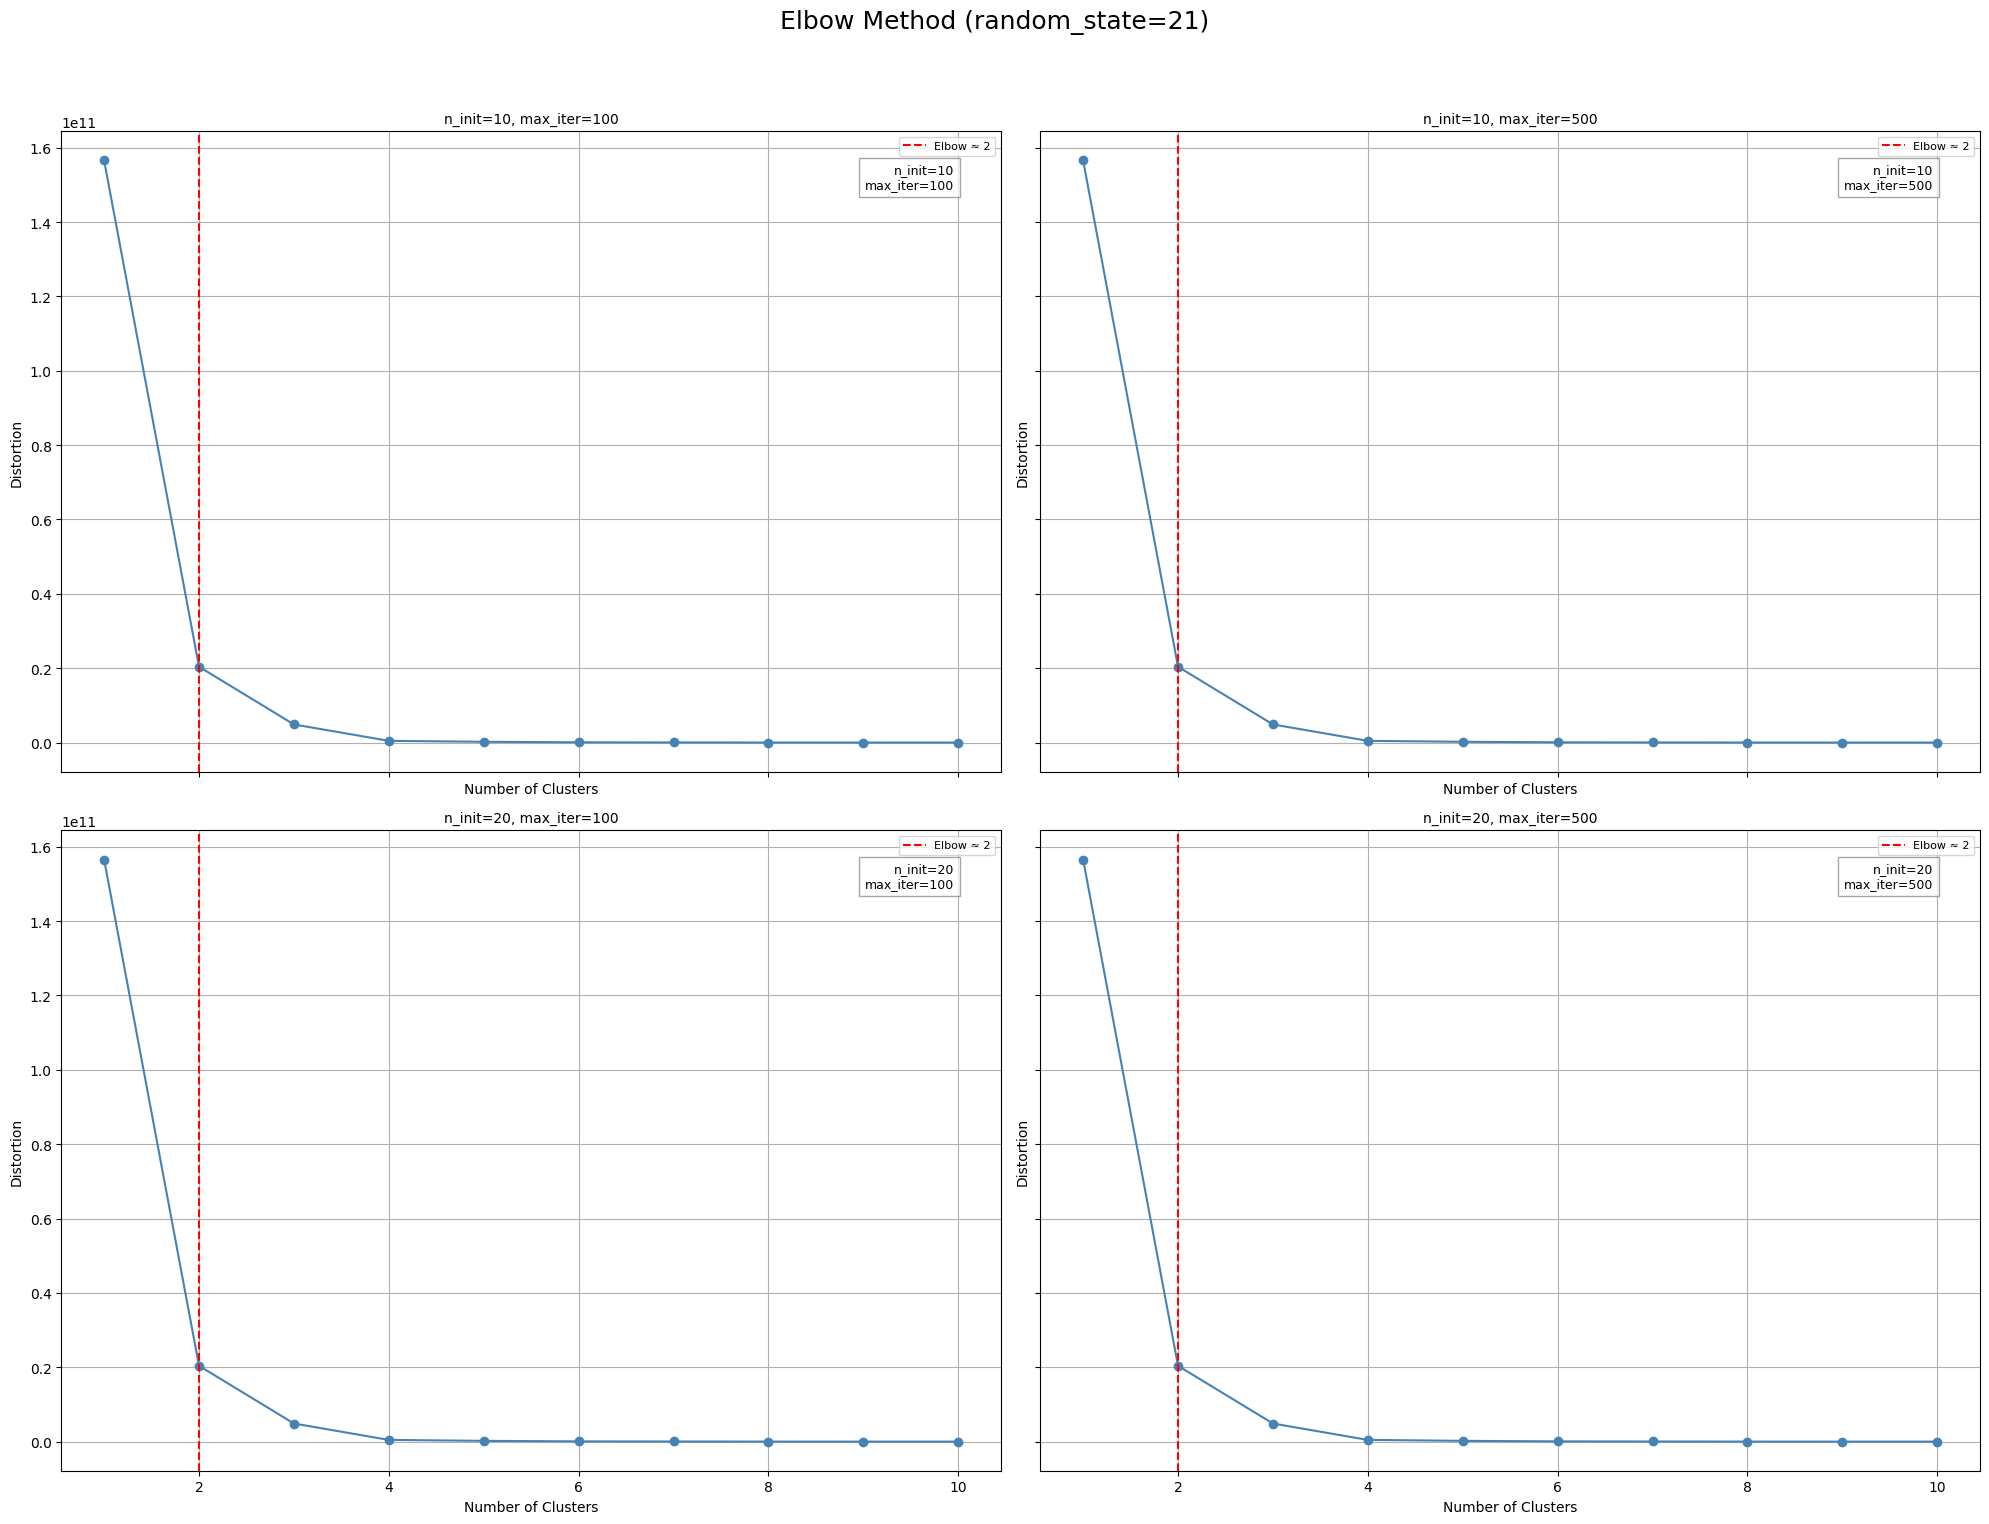


Running elbow plots for random_state=42


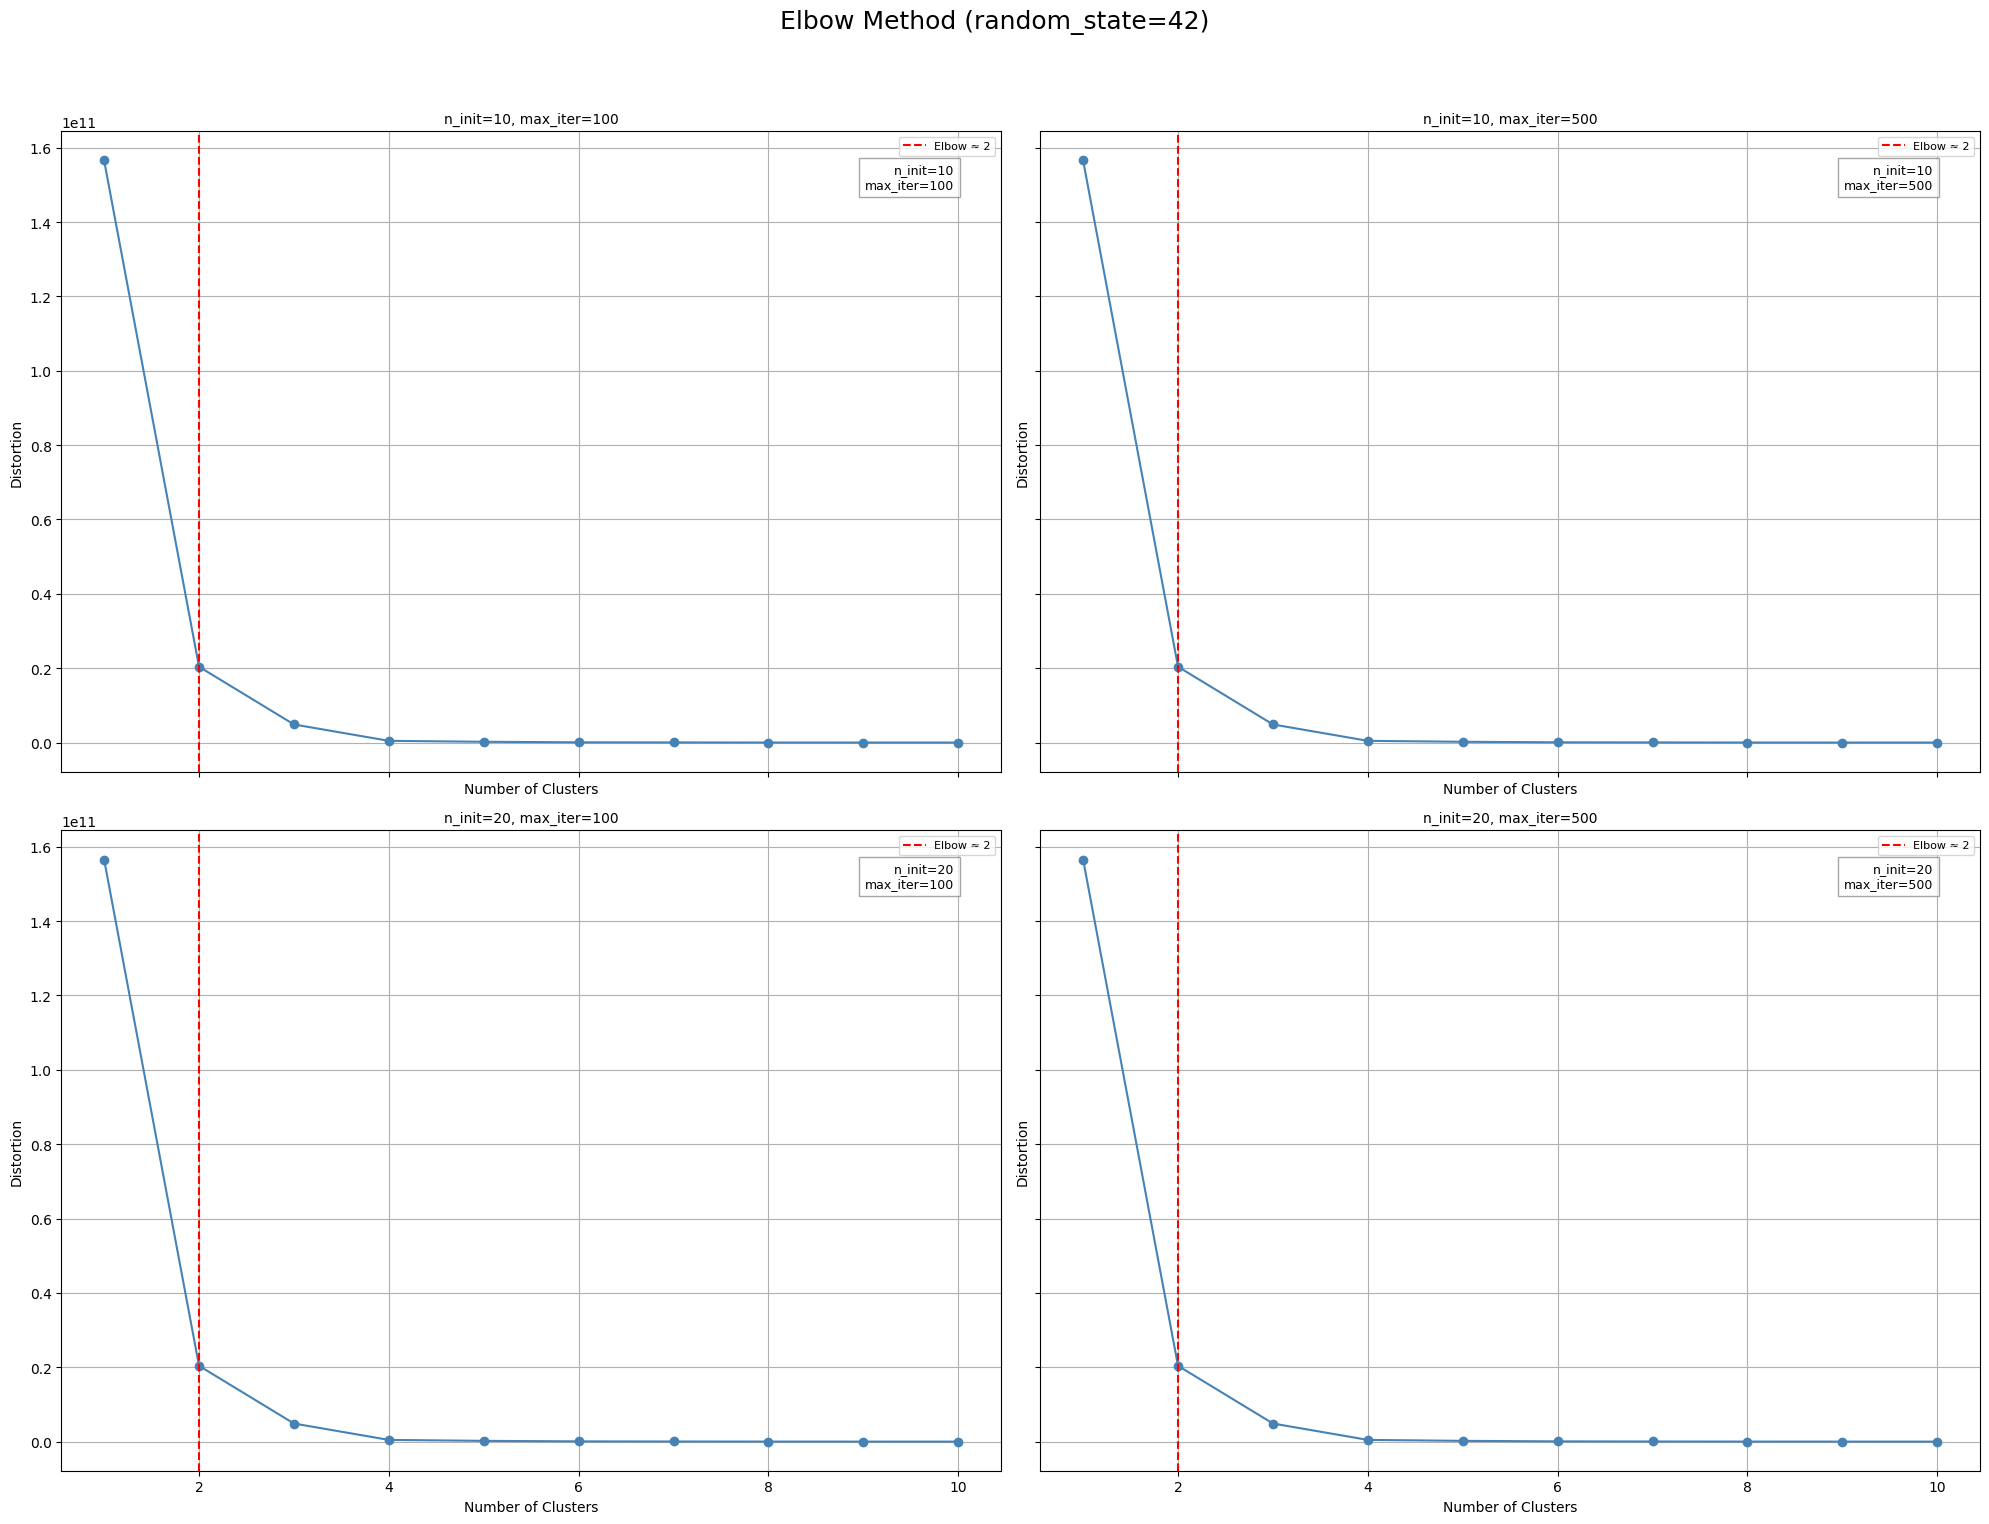


Total execution time: 6.80 seconds


In [16]:
# Start timer
start_time = time.time()

# Iterate over random states
for rs in random_states:
    print(f"\nRunning elbow plots for random_state={rs}")

    # Create figure grid
    fig, axes = plt.subplots(len(n_init_list), len(max_iter_list), figsize=(20, 16), sharex=True, sharey=True)
    fig.suptitle(f'Elbow Method (random_state={rs})', fontsize=18)

    # Iterate over parameter combinations
    for i, n_init in enumerate(n_init_list):
        for j, max_iter in enumerate(max_iter_list):
            distortions = []
            for k in n_clusters_range:
                km = KMeans(
                    n_clusters=k,
                    init='k-means++',
                    n_init=n_init,
                    max_iter=max_iter,
                    random_state=rs
                )
                km.fit(input_diff_3countries_deleted)
                distortions.append(km.inertia_)

            # Compute second derivative to find elbow
            second_derivative = np.diff(distortions, n=2)
            elbow_point = np.argmax(second_derivative) + 2  # +2 to align with cluster count

            # Plot
            ax = axes[i, j]
            ax.plot(n_clusters_range, distortions, marker='o', linestyle='-', color='steelblue')
            ax.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
            ax.set_title(f'n_init={n_init}, max_iter={max_iter}', fontsize=10)
            ax.set_xlabel('Number of Clusters')
            ax.set_ylabel('Distortion')
            ax.grid(True)
            ax.legend(loc='upper right', fontsize=8)

            # Annotate parameters inside plot
            ax.text(
                0.95, 0.95,
                f'n_init={n_init}\nmax_iter={max_iter}',
                transform=ax.transAxes,
                fontsize=9,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
            )

    # Final layout and display
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# End timer
end_time = time.time()
print(f"\nTotal execution time: {end_time - start_time:.2f} seconds")

#### Quantifying the quality of clustering via silhouette plots

The previous code was a nonsense since each iteration found the same elbow, so we will see if each iteration with a different hyperparameter results in a cluster with different members.

The code for each model will be as follows:
- cx = where c corresponds to 'clusters' and x corresponds to the number of clusters used
- nix = where ni corresponds to 'n_init' and x to the number of initializations used
- maxix = where maxi corresponds to 'max_iter' and x to the number of maximum iterations selected

In [17]:
from sklearn.metrics import silhouette_samples

In [18]:
from matplotlib import cm

In [19]:
def plot_silhouette(kmeans_model, X):
    """
    Generates a silhouette plot to evaluate the quality of KMeans clustering.

    Parameters:
    - kmeans_model: a fitted KMeans model.
    - X: the input feature matrix used for clustering.

    Returns:
    - silhouette_avg: the average silhouette coefficient across all samples.
    """
    labels = kmeans_model.labels_
    n_clusters = len(np.unique(labels))
    silhouette_vals = silhouette_samples(X, labels, metric='euclidean')
    silhouette_avg = np.mean(silhouette_vals)

    y_ax_lower, yticks = 0, []

    for i in range(n_clusters):
        cluster_vals = silhouette_vals[labels == i]
        cluster_vals.sort()
        y_ax_upper = y_ax_lower + len(cluster_vals)

        color = cm.jet(float(i) / n_clusters)
        plt.barh(
            range(y_ax_lower, y_ax_upper),
            cluster_vals,
            height=1.0,
            edgecolor='none',
            color=color
        )

        yticks.append((y_ax_lower + y_ax_upper) / 2.)
        y_ax_lower = y_ax_upper

    plt.axvline(silhouette_avg, color="red", linestyle="--", label=f"Average: {silhouette_avg:.2f}")
    plt.yticks(yticks, [f'Cluster {i+1}' for i in range(n_clusters)])
    plt.ylabel('Cluster')
    plt.xlabel('Silhouette coefficient')
    plt.title('Silhouette plot by cluster')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return silhouette_avg

In [20]:
km_c2_ni20_maxi500_diff_3countries_deleted = KMeans(n_clusters=2,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [22]:
ym_c2_ni20_maxi500_diff_3countries_deleted = km_c2_ni20_maxi500_diff_3countries_deleted.fit(input_diff_3countries_deleted)

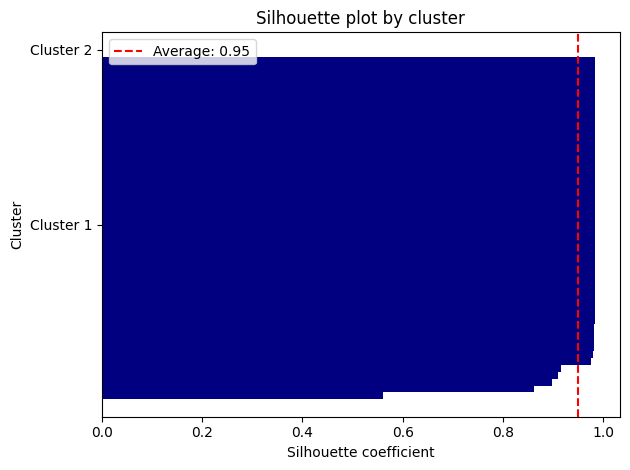

In [23]:
silhoutte_c2_ni20_maxi500_diff_3countries_deleted = plot_silhouette(ym_c2_ni20_maxi500_diff_3countries_deleted, input_diff_3countries_deleted)

In [24]:
np.bincount(ym_c2_ni20_maxi500_diff_3countries_deleted.labels_)

array([50,  1])

#### Make no sense only one cluster